# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [16]:
STUDENT_NAME = 'Кутельмах Євген Петрович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 8      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 8: Тернопіль, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [17]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [18]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [19]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True
ox.settings.log_console = True
ox.settings.overpass_endpoint = "https://overpass.openstreetmap.fr/api/interpreter"

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_тернопіль


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [20]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 1 ['65.109.112.52']
закріплено 65.109.112.52


'65.109.112.52'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [21]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0 = time.time()
    b0 = cache_bytes()

    g = clean(getter())
    g.to_parquet(path, index=False)

    COST[name] = {
        'спосіб': 'живий запит',
        'записів': len(g),
        'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
        'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
        'секунд': round(time.time() - t0, 3)
    }
    
    return g

In [22]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 58.6 км²


In [23]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14314 | ребер 38950


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [24]:
df_cost = pd.DataFrame(COST).T
display(df_cost)

total_time = df_cost['секунд'].sum()
total_file_mb = df_cost['файл_МБ'].sum()
total_transferred_mb = df_cost['передано_МБ'].sum()

print(f"\nЗагальний час виконання: {total_time:.3f} сек")
print(f"Загальний розмір файлів: {total_file_mb:.3f} МБ")

if (df_cost['спосіб'] == 'знімок').all():
    print(f"Кеш - Мережею не передано: {total_file_mb:.3f} МБ.")
else:
    print(f"Живий запит - Передано мережею: {total_transferred_mb:.3f} МБ.")

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.022,0.067
heritage,знімок,266,0.0,0.097,0.031
stations,знімок,4,0.0,0.031,0.02
amenities,знімок,247,0.0,0.075,0.024
мережа walk,знімок,53264,0.0,2.744,0.064



Загальний час виконання: 0.206 сек
Загальний розмір файлів: 2.969 МБ
Кеш - Мережею не передано: 2.969 МБ.


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

Живий запит: 232.791 сек / 6.609 МБ

Кеш: 0.142 сек / 0 МБ

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [25]:
# ----- ВАШ КОД -----
mask = heritage['historic'].notna() | heritage['tourism'].notna()

cand = heritage[mask & heritage['name'].notna()]
cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', mask.sum())
print('з них мають name       :', len(cand))

total_rejected = len(heritage) - len(cand)
rejected_no_name = mask.sum() - len(cand)

if total_rejected == rejected_no_name:
    print(f'Усього відкинуто об\'єктів: {total_rejected}, бо хоч і мають потрібні теги, але не мають тега name')

усього у шарі heritage : 266
підходять за тегами    : 266
з них мають name       : 218
Усього відкинуто об'єктів: 48, бо хоч і мають потрібні теги, але не мають тега name


In [26]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial    152
tomb          1
monument      1
stone         1
castle        1

=== tourism ===
tourism
artwork       40
attraction    23
museum         8
viewpoint      1

типи геометрії: {'Point': 205, 'Polygon': 13}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [27]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# ----- ВАШ КОД -----
has_wp = cand['wikipedia'].notna() if 'wikipedia' in cand.columns else pd.Series(False, index=cand.index)
has_wd = cand['wikidata'].notna() if 'wikidata' in cand.columns else pd.Series(False, index=cand.index)
cand['wiki'] = (has_wp | has_wd).astype(int)

name_cols = [c for c in cand.columns if str(c).startswith('name:')]
cand['n_lang'] = cand[name_cols].notna().sum(axis=1)

cand['is_museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)

cand['score'] = (
    0.36 * cand['wiki'].rank(pct=True) +
    0.47 * cand['n_lang'].rank(pct=True) +
    0.17 * cand['is_museum'].rank(pct=True)
)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))

кандидатів   : 218
мають wiki   : 28


Я обрав ваги 0.47 для кількості мов - оскільки це показує міжнародний статус об'єкта, 0.36 для вікі - локальний статус, 0.17 якщо об'єкт є музеєм або галереєю - збільшує цікавість до теми та спрощує дізнавання про неї.

### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [28]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap   = top10['name'].isin(top_naive['name']).sum()
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 2 з 10


,за вашим критерієм,за площею
0,Тернопільський краєзнавчий музей,Тернопільський замок
1,Музей політичних в’язнів,Тернопільський краєзнавчий музей
2,Тернопільський замок,Пам’ятний знак героям ОУН-УПА
3,Соломії Крушельницькій,Вічний вогонь
4,Степану Бандері,Військове кладовище
5,Іванові Франку,Місток
6,Горбачевському Івану,Св. Іван Непомук
7,Обласний художній музей,Місток
8,Картинна галерея,Альтанка;Острів Кохання
9,В пам'ять розстріляних євреїв,Танк т-34


Результати різні, адже найкращий площею - найбільший, найкращий за введеною метрикою, той, який відносно несе більше історичної цінності 

### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [29]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----
pairs = close_pairs(top_score, limit_m=60)

print(f"Знайдено {len(pairs)} пар(у) об'єктів на відстані ближче 60 метрів:\n")

for i, j, dist in pairs:
    name1 = top_score.loc[i, 'name']
    name2 = top_score.loc[j, 'name']
    print(f"{dist:.1f} м: {name1} — {name2}")

Знайдено 5 пар(у) об'єктів на відстані ближче 60 метрів:

13.8 м: Горбачевському Івану — Загиблим євреям
28.3 м: Випадкова зустріч — Тристоронній годинник
46.4 м: Незалежності — Тристоронній годинник
51.7 м: Шептицькому Андрею — Пам’ятник жертвам депортації 1944-1946 років з Лемківщини, Холмщини, Надсяння
52.9 м: Іванові Франку — Картинна галерея


Було вирішено залишити об'єкти, що знаходяться поруч, оскільки усі пари містять незалежні між собою об'єкти

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [30]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 4
                  name  railway       building
0               151 км     halt            NaN
1  Тернопіль-Вантажний     halt            NaN
2            Тернопіль  station            NaN
3     Вокзал Тернопіль      NaN  train_station


In [31]:
# ----- ВАШ КОД -----
station = stations[stations['railway'] == 'station']
print('старт:', station['name'].iloc[0])

старт: Тернопіль


In [32]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14314 вузлів, 38506 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [33]:
def check_snap(points, ids, dist, label):
    unique_ids, counts = np.unique(ids, return_counts=True)
    n_points = len(ids)
    n_unique = len(unique_ids)
    
    print(f"--- {label} ---")
    print(f"Точок: {n_points} | Різних вузлів: {n_unique}")
    print(f"Відстань до найближчого вузла: медіана = {np.median(dist):.1f} м, максимум = {np.max(dist):.1f} м")
    
    if n_unique < n_points:
        print("Наступні точки злиплись:")
        for node_id, count in zip(unique_ids, counts):
            if count > 1:
                idx = np.where(ids == node_id)[0]
                names = points['name'].iloc[idx].tolist()
                print(f" -> {', '.join(names)}")
    print()

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [34]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    # ----- ВАШ КОД: матриця прямих віддалей у метрах -----
    pmet = points.to_crs(32635)
    XY = np.c_[pmet.geometry.x.values, pmet.geometry.y.values]
    E = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    return E

def detour_factor(D, E):
    # ----- ВАШ КОД: медіана відношення дорога / пряма, по скінченних парах -----
    valid = (E > 0) & np.isfinite(D)
    ratios = D[valid] / E[valid]
    return np.median(ratios)

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [35]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

--- мала задача ---
Точок: 11 | Різних вузлів: 11
Відстань до найближчого вузла: медіана = 14.7 м, максимум = 26.6 м

матриця за 0.307 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.27


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

У мене асиметрія 0, отже усі вузли з'єднані двосторонніми дорогами (що очікувано для пішоходної мережі)

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [36]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    n = len(D)
    unvisited = set(range(1, n))
    tour = [0]
    
    while unvisited:
        curr = tour[-1]
        nxt = min(unvisited, key=lambda node: D[curr, node])
        tour.append(nxt)
        unvisited.remove(nxt)
        
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best_tour = list(tour)
    improved = True
    
    while improved:
        improved = False
        for i in range(1, len(best_tour) - 2):
            for j in range(i + 1, len(best_tour) - 1):
                new_tour = best_tour[:i] + best_tour[i:j+1][::-1] + best_tour[j+1:]
                
                if tour_length(D, new_tour) < tour_length(D, best_tour) - 1e-6:
                    best_tour = new_tour
                    improved = True
                    break
            if improved:
                break
                
    return best_tour

In [37]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [38]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [39]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,8632,15.58
2-opt,7617,1.99
Held-Karp (точний),7468,0.00



оптимальний порядок:
   0. СТАРТ: Тернопіль
   1. Обласний художній музей
   2. Степану Бандері
   3. Тернопільський замок
   4. Горбачевському Івану
   5. В пам'ять розстріляних євреїв
   6. Тернопільський краєзнавчий музей
   7. Картинна галерея
   8. Іванові Франку
   9. Соломії Крушельницькій
  10. Музей політичних в’язнів
  11. СТАРТ: Тернопіль

довжина: 7.47 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [40]:
# ----- ВАШ КОД: таблиця зростання -----
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = (2 ** (n - 1)) * (n - 1)
    gb = (cells * 8) / (1024 ** 3)
    
    rows.append({
        'n (кількість точок)': n,
        'Клітин у таблиці': cells,
        'Пам\'ять (ГБ)': gb
    })

df_memory = pd.DataFrame(rows)
display(df_memory.style.format({'Клітин у таблиці': '{:,}', 'Пам\'ять (ГБ)': '{:.6f}'}))

,n (кількість точок),Клітин у таблиці,Пам'ять (ГБ)
0,11,"10,240",0.000076
1,16,"491,520",0.003662
2,21,"20,971,520",0.156250
3,26,"838,860,800",6.250000
4,31,"32,212,254,720",240.000000


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

За умови звичайного комп'ютера, точний розв'язок для 30 точок неможливий - оскільки таблиця займатиме 240 Гігабайт оперативної пам'яті, що перевершує будь-які стандарти звичайних ПК

In [41]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

--- велика задача ---
Точок: 31 | Різних вузлів: 31
Відстань до найближчого вузла: медіана = 13.4 м, максимум = 64.7 м

коефіцієнт обходу: 1.25
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    19166 м
2-opt            :    17497 м  за 0.058 с  (коротше на 8.7%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


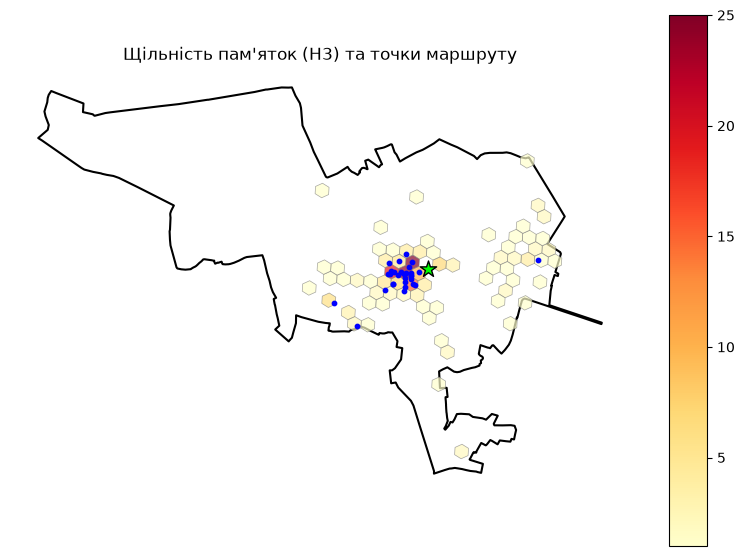

Загалом кандидатів: 218
Половина всіх пам'яток зосереджена лише у 8 комірках із 70.


In [42]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
pts = cand.to_crs(4326).geometry.representative_point()

cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts]

dens = cand['h3'].value_counts().reset_index()
dens.columns = ['h3', 'count']

hexes = gpd.GeoDataFrame(
    dens, 
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)]) for cell in dens['h3']], 
    crs='EPSG:4326'
)

fig, ax = plt.subplots(figsize=(10, 10))

boundary.to_crs(4326).plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.5, zorder=1)

hexes.plot(ax=ax, column='count', cmap='YlOrRd', alpha=0.7, edgecolor='gray', 
           linewidth=0.5, legend=True, zorder=2)

route_pts = make_points(top_score.head(30))
route_pts.plot(ax=ax, color='blue', markersize=10, zorder=3)

route_pts.iloc[[0]].plot(ax=ax, color='lime', marker='*', markersize=150, edgecolor='black', zorder=4)

ax.set_title('Щільність пам\'яток (H3) та точки маршруту')
ax.set_axis_off()
plt.show()

dens_sorted = dens.sort_values('count', ascending=False)

total_landmarks = dens['count'].sum()
half_landmarks = total_landmarks / 2

cumsum = dens_sorted['count'].cumsum()

cells_for_half = (cumsum < half_landmarks).sum() + 1

print(f"Загалом кандидатів: {total_landmarks}")
print(f"Половина всіх пам'яток зосереджена лише у {cells_for_half} комірках із {len(dens)}.")

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту? - У 8 комірках зосереджено половину пам'яток, тому форма машруту - це круг у центрі з декількома "променями" до пам'яток на окраїні

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [43]:
# ----- ВАШ КОД -----
route_m = route_pts.to_crs(32635)
amenities_m = amenities.to_crs(32635)

nearest = gpd.sjoin_nearest(
    route_m, 
    amenities_m, 
    how='left', 
    distance_col='відстань_м',
    lsuffix='маршрут', 
    rsuffix='заклад'
)

result_table = nearest[['name_маршрут', 'name_заклад', 'amenity', 'відстань_м']].copy()
result_table.columns = ['Точка маршруту', 'Найближчий заклад', 'Тип', 'Відстань (м)']

result_table['Відстань (м)'] = result_table['Відстань (м)'].round(1)

display(result_table)

,Точка маршруту,Найближчий заклад,Тип,Відстань (м)
0,СТАРТ: Тернопіль,NaN,toilets,37.7
1,Тернопільський краєзнавчий музей,Дружня ресторація „Мамонт“,restaurant,41.3
2,Музей політичних в’язнів,Tikithai,cafe,40.0
3,Тернопільський замок,Веранда,restaurant,30.0
4,Соломії Крушельницькій,Хінкальня,restaurant,57.5
5,Степану Бандері,NaN,toilets,137.1
6,Іванові Франку,NaN,cafe,35.3
7,Горбачевському Івану,Eggo Coffee,cafe,64.7
8,Обласний художній музей,Шеф Панда,cafe,109.1
9,Картинна галерея,Карма Кава,cafe,14.1


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [44]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД: folium.Map(..., tiles=BASEMAP), дві PolyLine, маркери з номерами -----
# не забудьте fmap.save('lr5_маршрут.html')

real_coords = route_coords(op30, ids30)

straight_coords = []
for i in op30:
    geom = pts30.to_crs(4326).geometry.iloc[i]
    straight_coords.append((geom.y, geom.x))

start_lat, start_lon = straight_coords[0]
fmap = folium.Map(location=[start_lat, start_lon], zoom_start=14, tiles='CartoDB positron')

folium.PolyLine(
    straight_coords,
    color='red',
    weight=2,
    dash_array='8, 8',
    opacity=0.6,
    tooltip='Прямі відрізки'
).add_to(fmap)

folium.PolyLine(
    real_coords,
    color='blue',
    weight=4,
    opacity=0.8,
    tooltip='Маршрут вулицями'
).add_to(fmap)

for step, point_idx in enumerate(op30[:-1]):
    lat, lon = straight_coords[step]
    name = pts30['name'].iloc[point_idx]
    
    color = 'green' if step == 0 else 'blue'
    
    folium.Marker(
        location=[lat, lon],
        tooltip=f"Крок {step}: {name}",
        popup=f"<b>Крок {step}</b><br>{name}",
        icon=folium.Icon(color=color, icon='info-sign')
    ).add_to(fmap)

fmap.save('lr5_маршрут.html')
fmap

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [45]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.5 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [ ]:
REPORT = '''
1. На кроці 2 було відкинуто 48 об'єктів. У кожного з них в базі немає назви, цей об'єкт ігнорується, навіть якщо він має історичну цінність. Віддавати такий фільтр замовнику без пояснень не варто - є ризик, що при заповненні даних забули вказати ім'я, тому такі рішення обов'язково треба пояснювати
2. Сконструйований рейтинг спирається на три критерії: кількість мов (вага 0.47), наявність Вікіпедії (0.36) та статус музею/галереї (0.17). Логіка така: що більше перекладів, то відоміша пам'ятка у світі, Вікіпедія гарантує, що місце має локальну культурну цінність, а статус музею дає бонус за те, що туристу легше заглибитись в історичну тематику
3. У топі за розробленим рейтингом і за найпростішим критерієм площі збіглося всього 2 об'єкти. Це показує, що найкращого не існує — усе вирішує обрана метрика. Якщо обирати за площею, туриста відправлять гуляти складами, що зовсім не відповідає його меті
4. Отриманий коефіцієнт обходу становить 1.27 для 11 точок та 1.25 для великої задачі. Це типовий показник для пішохідної мережі (норма 1.2–1.6). Він означає, що в місті зручна сітка вулиць і немає нездоланних перешкод
5. Маршрут "найближчого сусіда" виявився на 15.58% довшим за ідеальний розв'язок Held-Karp. Ні, результат не здивував, оскільки метод "найближчого сусіда" є евристичним
6. Знайти точний розв'язок для 30 пам'яток плюс вокзал неможливо через брак оперативної пам'яті. Алгоритм росте експоненціально, і для 31 точки його таблиця займе 32 212 254 720 клітин. Це вимагає 240 ГБ оперативної пам'яті
7. Недоліки присутні - було 48 об'єктів без назв, які довелося викинути з кандидатів. Також було знайдено 5 пар локацій на відстані ближче 60 метрів один від одного, проте було вирішено їх залишити, бо виявилося, що це просто різні об'єкти поруч, а не дублікати

Декларація про використання ШІ:
Користувався Gemini argon, у завданнях 4, 5, 6, 7, 9, зокрема для реалізації алгоритмів розв'язку задачі Комі Вояжера та побудови інтерактивної мапи, перевіряв код внаслідок логічного аналізу
'''
print(REPORT)


1.
2.
3.
4.
5.
6.
7.

Декларація про використання ШІ:

